In [112]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
folderPath = "../images"
os.makedirs(folderPath, exist_ok=True)

In [113]:
data = pd.read_csv("../data/Superstore.csv", encoding="latin1")
data["Order Date"] = pd.to_datetime(data["Order Date"])
print(data["Order Date"])

0      2016-11-08
1      2016-11-08
2      2016-06-12
3      2015-10-11
4      2015-10-11
          ...    
9989   2014-01-21
9990   2017-02-26
9991   2017-02-26
9992   2017-02-26
9993   2017-05-04
Name: Order Date, Length: 9994, dtype: datetime64[us]


In [114]:
totalRev = data["Sales"].sum()
totalProfit = data["Profit"].sum()
topCategory = data.groupby("Category")["Sales"].count().idxmax()
topCategoryByRev = data.groupby("Category")["Sales"].sum().idxmax()
topSubCategory = data.groupby("Sub-Category")["Sales"].count().idxmax()
topSubCategoryByRev = data.groupby("Sub-Category")["Sales"].sum().idxmax()
topRegion = data.groupby("Region")["Sales"].sum().idxmax()
lossProduct = data.groupby("Product Name")["Profit"].sum().idxmin()
topMonth = data.groupby(data["Order Date"].dt.to_period("M"))["Sales"].count().idxmax()
avgDiscount = data["Discount"].mean()
topCustomer = data.groupby("Customer Name")["Sales"].sum().idxmax()
disProCorr = data["Discount"].corr(data["Profit"])

print("========== RETAIL PULSE ANALYSIS ==========")
print("Total Revenue:", totalRev)
print("Total Profit:", totalProfit)
print("Top Category:", topCategoryByRev)
print("Top Sub-Category:", topSubCategoryByRev)
print("Top Region:", topRegion)
print("Highest Sales Month:", topMonth)
print("Average Discount:", avgDiscount)
print("Top Customer:", topCustomer)
print("==========================================")

========== RETAIL PULSE ANALYSIS ==========
Total Revenue: 2297200.8603
Total Profit: 286397.0217
Top Category: Technology
Top Sub-Category: Phones
Top Region: West
Highest Sales Month: 2017-12
Average Discount: 0.1562027216329798
Top Customer: Sean Miller


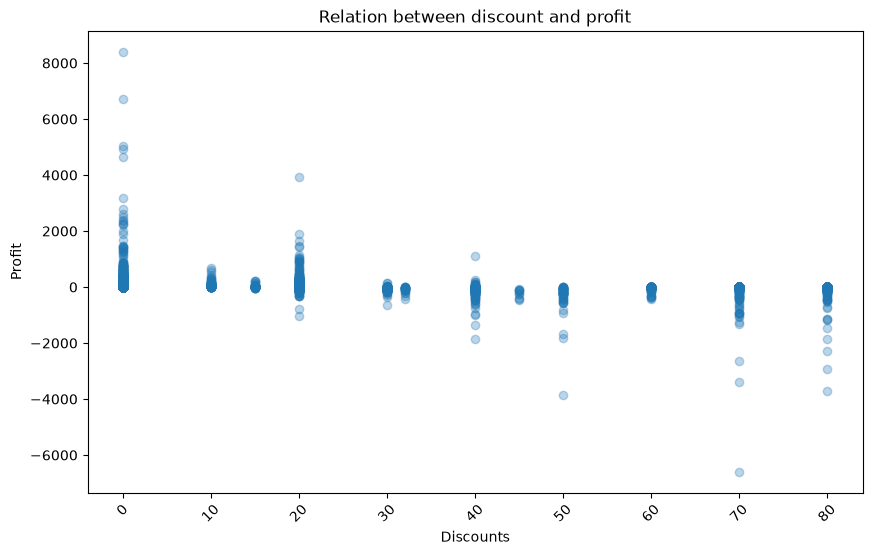

In [115]:
plt.figure(figsize=(10,6))
plt.scatter(data["Discount"]*100,data["Profit"],alpha=0.3)
plt.xlabel("Discounts")
plt.ylabel("Profit")
plt.title("Relation between discount and profit")
plt.xticks(rotation=45)
plt.show()

In [116]:
#Spoiling Dataset with a maths
sales = data["Sales"].to_numpy()
meanSale = np.mean(sales)
sdSales = np.std(sales,ddof=1)

p25 = np.percentile(sales, 25)
p50 = np.percentile(sales, 50)
p75 = np.percentile(sales, 75)
p90 = np.percentile(sales, 90)

total_sales = np.sum(data["Sales"].to_numpy())
total_profit = np.sum(data["Profit"].to_numpy())

profit_margin = np.divide(total_profit, total_sales) * 100

print("25th Percentile:", p25)
print("50th Percentile:", p50)
print("75th Percentile:", p75)
print("90th Percentile:", p90)
print("Total Sales:", total_sales)
print("Total Profit:", total_profit)
print("Profit Margin:", profit_margin, "%")

25th Percentile: 17.28
50th Percentile: 54.489999999999995
75th Percentile: 209.94
90th Percentile: 572.7060000000001
Total Sales: 2297200.8603
Total Profit: 286397.0217
Profit Margin: 12.467217240315605 %


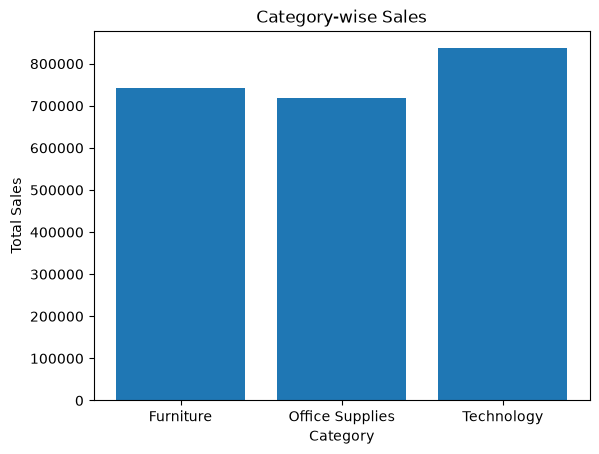

In [117]:
#Category Wise Sales
categorySales = data.groupby("Category")["Sales"].sum()
plt.bar(categorySales.index, categorySales.values)
plt.title("Category-wise Sales")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.savefig(os.path.join(folderPath, "category_sales.png"), dpi=300, bbox_inches="tight")
plt.show()


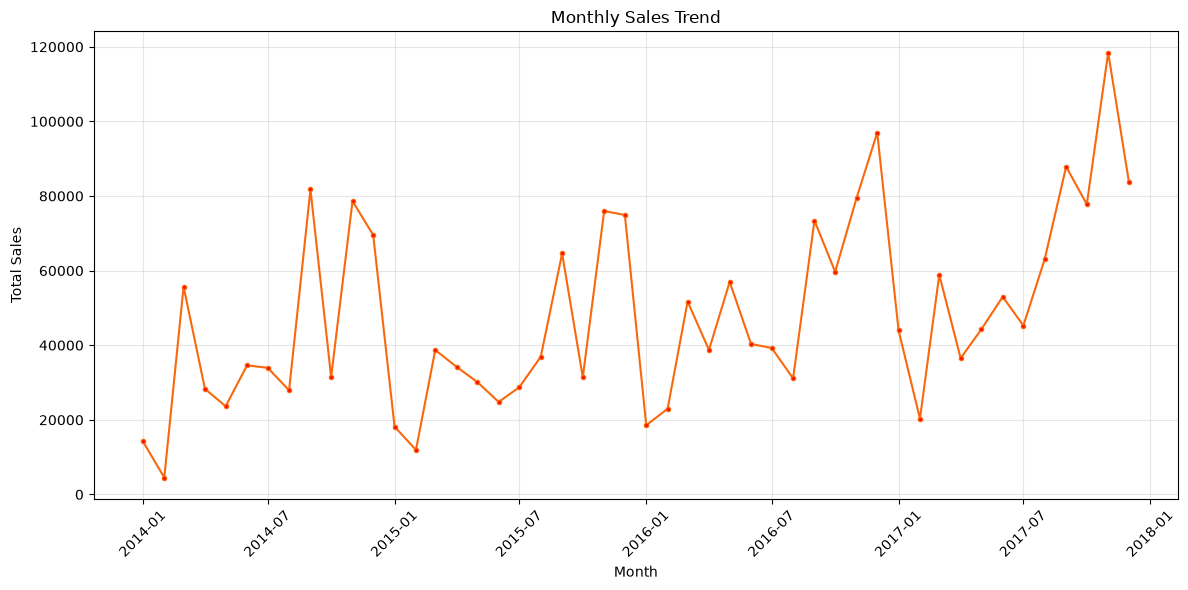

In [118]:
# Monthly Sales Trend

months = data.groupby(
    data["Order Date"].dt.to_period("M")
)["Sales"].sum()

plt.figure(figsize=(12, 6))

plt.plot(
    months.index.to_timestamp(),
    months.values,
    marker=".",
    markerfacecolor="red",
    color="#f9680d"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(folderPath, "monthly_sales.png"), dpi=300, bbox_inches="tight")
plt.show()

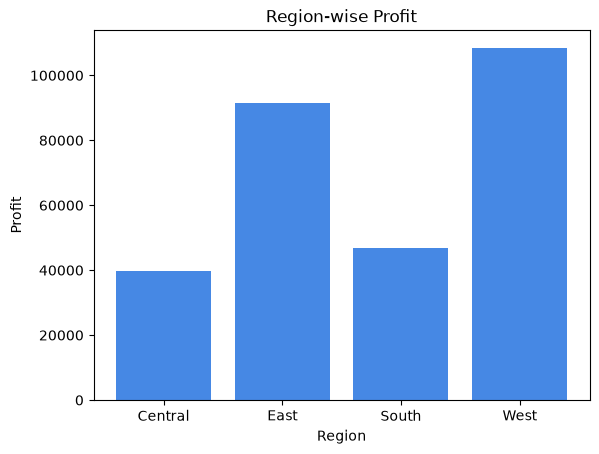

In [119]:

#Region Wise Profit
regionProfit = data.groupby("Region")["Profit"].sum()
plt.bar(regionProfit.index, regionProfit.values,color="#176adecb")
plt.title("Region-wise Profit")
plt.xlabel("Region")
plt.ylabel("Profit")
plt.savefig(os.path.join(folderPath, "regional_profit.png"), dpi=300, bbox_inches="tight")
plt.show()


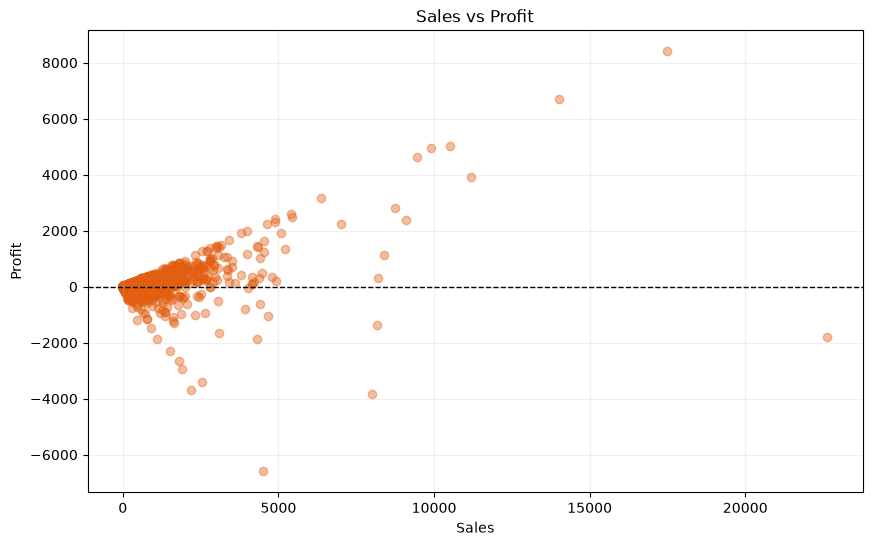

In [120]:
#Sales vs Profit
plt.figure(figsize=(10, 6))

plt.scatter(
    data["Sales"],
    data["Profit"],
    color="#e25e11",
    alpha=0.4
)

plt.axhline(y=0, color="black", linestyle="--", linewidth=1)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.grid(alpha=0.2)
plt.savefig(os.path.join(folderPath, "sales_vs_profit.png"), dpi=300, bbox_inches="tight")
plt.show()

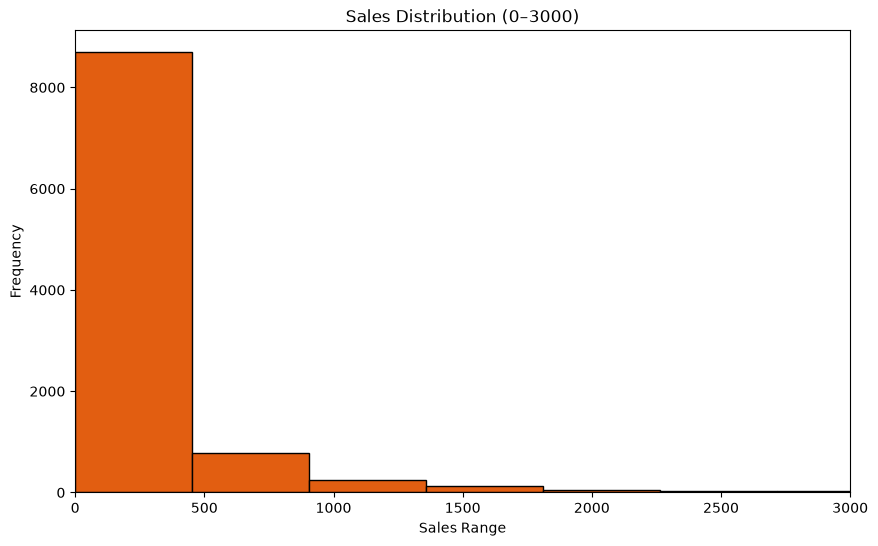

In [121]:
# Sales Distribution
plt.figure(figsize=(10, 6))
plt.hist(data["Sales"], bins=50, color="#e25e11", edgecolor="black")
plt.xlim(0, 3000)
plt.title("Sales Distribution (0–3000)")
plt.xlabel("Sales Range")
plt.ylabel("Frequency")
plt.savefig(os.path.join(folderPath, "Sales_Distribution.png"),dpi = 300,bbox_inches="tight")
plt.show()